# <DEVICE> — Analysis

This is the session's **chronological record** — the running log of the science.
Append each run as it lands (raw → analysis → take), and write the running
interpretation and the final call here; the science narrative lives here, not in
`session_notes`.

Launch point over `hera.analysis` — the data layer for spxtr/measureme `sweep`
runs (`data/<i>/data.tsv[.gz]` + `metadata.json`). Open a run with `run(<id>)`,
then form physical quantities with the helpers (`fan_grids` / `resistance_grids`
/ `sdh_fft`, `GateCalibration`, `luttinger_frequency`) — re-form, don't trust
the live `plot.png`. Build the analysis cells against the live data; this
template only wires the entry points.

`metadata.hera.policy = edit_exec` — the agent may edit/append/execute cells
here. Measurement cells live on the measure notebook.

In [1]:
import numpy as np
import scipy.constants as cst
import matplotlib.pyplot as plt

from pathlib import Path

from hera.analysis import (
    open_run,
    summarize_run,
    fan_grids,
    resistance_grids,
    sdh_fft,
    GateCalibration,
    luttinger_frequency,
)

%matplotlib inline


def _resolve_data_dir():
    """Locate this run's ./data dir from the notebook's own location.

    The ana kernel's cwd is not guaranteed to be the measurement dir, so a
    bare './data' breaks loaders with FileNotFoundError. IPython sets
    globals()['_dh'] to a list whose first entry is the notebook's startup
    cwd (the dir holding the notebook); this survives jupyter-collaboration/
    RTC and any later %cd, so we prefer it. We fall back to Path.cwd() and
    search a few levels up so loading still works if the kernel started inside
    ./data/<id>/. The walk stops before the filesystem root so an unrelated
    top-level 'data' dir can never be matched.
    """
    candidates = []
    dh = globals().get("_dh")
    if dh:
        candidates.append(Path(dh[0]))
    candidates.append(Path.cwd())
    for base in candidates:
        base = Path(base).resolve()
        for d in [base, *base.parents]:
            if d == d.parent:  # filesystem root
                break
            cand = d / "data"
            if cand.is_dir():
                return str(cand)
    return str((Path(candidates[0]) / "data").resolve())


file_path = _resolve_data_dir()


# Open a run by id: run(119) -> Run. Run.col(name) for a column;
# summarize_run(run(119)) for a recipe / range / completeness / T glance.
def run(i):
    return open_run(Path(file_path) / str(i))

## (n, D) — capacitance-based convention

`GateCalibration` carries the gate->(n, D) lever arm: `cal.n_D(V_tg, V_bg)`
returns `n` in SI (m^-2; ×1e-16 for 10^12 cm^-2) and `D` in V/m. Build it from
the gate-stack thicknesses with `from_thicknesses` (κ_hBN/κ_SiO2 default).
This is the capacitance convention, **not** the toploader's `dtg/dbg` constant
form. Set `n_offset` / `D_offset` from `cnp-and-dline-calibration` once the CNP
/ D-line is live.

In [2]:
# slot: geometry — gate-stack thicknesses (device card) + in-session (n,D) cal.
t_tg = 23.6e-9   # top-gate hBN thickness, m
t_bg = 20e-9     # back-gate hBN thickness, m
t_bgSiO2 = 0     # SiO2 term, m — zero for a graphite back gate

# Session gate calibration — run-4 CNP-ridge fit (cnp-and-dline-calibration):
# ratio data-pinned (c_tg/c_bg=0.844, agrees geometry prior 99.5%); absolute
# scale = geometry prior; n_offset shifts CNP -> n=0. USE EXACTLY (handoff §1).
N_OFF = -0.362e11 * 1e4   # m^-2
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2, n_offset=N_OFF)
# display units: n[1e11 cm^-2] = cal.n_D(Vtg,Vbg)[0]/1e4/1e11 ; D[V/nm] = [1]/1e9


## Analysis discipline — raw first, then the read

For every run, in order: **(1) plot the raw run**; **(2) then the analysis** via the `hera.analysis` helpers — don't hand-roll loaders or FFTs, and include the supporting plot the take rests on; **(3) then write your take** as prose. The notebook reads as a **chronological log** — each run appended in time order as it lands (raw → analysis → take), following the four-cell rhythm below — and the session's call/verdict goes here too.

## Run 0 — re-entry baseline: constant-D n-cut at D = −0.64 V/nm

Why / what we're testing: gate-C re-entry. Does the SC dome survive the handover to this fresh session/kernel? A fast 1D n-cut at the provisional widest-point D=−0.64 (n −4.0→−6.0×10¹¹, 41 pts, AC 1 nA, 4T sens 1 mV, B≈0, base T) should show Rxx(4T, 30-31)→~0 near n≈−5.0×10¹¹ with normal flanks both sides — quantitatively matching prior runs 5–8.


run 0
  type:    1D sweep
  recipe:  re-entry-baseline
  tags:    constant-D n-linecut (gate-C re-entry); reproduce SC dome arc vs prior runs 5-8, re-entry baseline; constant-D n-cut D=-0.64 V/nm; n -4.0->-6.0e11 (0.05 step), 41 pts; AC 1 nA; 4T sens 1 mV; B~0, base T
  rows:    41 of 2 (41/2 (no interrupt flag, row count differs))
  T:       mean 0.034 K (range 0.034 – 0.034)


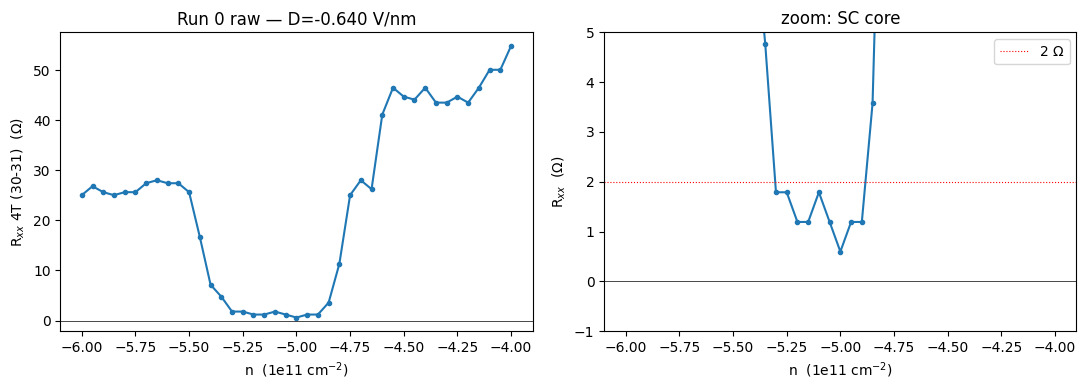

In [3]:
# Run 0 — raw: re-entry baseline, constant-D n-cut at D=-0.64
g = run(0)
print(summarize_run(g))
vtg = g.col_at(g.col_indices('k_tg_volt')[0]); vbg = g.col_at(g.col_indices('k_bg_volt')[0])
n11 = cal.n_D(vtg, vbg)[0] / 1e4 / 1e11
D_Vnm = cal.n_D(vtg, vbg)[1] / 1e9
I_bias = 1e-9
R3 = (g.col_at(g.col_indices('sr830_3_X')[0]) / 100) / I_bias   # 4T Rxx (30-31)
R2 = (g.col_at(g.col_indices('sr830_2_X')[0]) / 100) / I_bias   # 2T (5-4)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(n11, R3, '-o', ms=3)
ax[0].set_xlabel('n  (1e11 cm$^{-2}$)'); ax[0].set_ylabel('R$_{xx}$ 4T (30-31)  ($\\Omega$)')
ax[0].set_title(f'Run 0 raw — D={D_Vnm.mean():.3f} V/nm'); ax[0].axhline(0, color='k', lw=0.5)
ax[1].plot(n11, R3, '-o', ms=3); ax[1].set_ylim(-1, 5); ax[1].axhline(0, color='k', lw=0.5)
ax[1].axhline(2, color='r', ls=':', lw=0.8, label='2 $\\Omega$')
ax[1].set_xlabel('n  (1e11 cm$^{-2}$)'); ax[1].set_ylabel('R$_{xx}$  ($\\Omega$)')
ax[1].set_title('zoom: SC core'); ax[1].legend()
plt.tight_layout(); plt.show()


In [4]:
# Run 0 — analysis: locate the dome minimum & core, check leakage / T
imin = np.argmin(R3)
core = (R3 < 2.0)
itg = np.abs(g.col('k_tg_curr')).max(); ibg = np.abs(g.col('k_bg_curr')).max()
print(f"Rxx min = {R3[imin]:.3f} Ohm at n = {n11[imin]:.3f}e11 "
      f"(V_tg={vtg[imin]:.3f}, V_bg={vbg[imin]:.3f})")
if core.any():
    print(f"Rxx<2 Ohm core: n in [{n11[core].min():.2f}, {n11[core].max():.2f}]e11 "
          f"({core.sum()} pts)")
print(f"normal flanks: n={n11[0]:.2f} -> {R3[0]:.1f} Ohm ; n={n11[-1]:.2f} -> {R3[-1]:.1f} Ohm")
print(f"leakage max: |I_tg|={itg:.2e} A, |I_bg|={ibg:.2e} A  (both << 1 nA)")
print(f"T held: {g.col('T').mean()*1e3:.1f} mK")
print("compare prior: optimum n=-5.0e11, D=-0.64 -> V_tg=-5.365, V_bg=+3.987 (runs 5-8)")


Rxx min = 0.596 Ohm at n = -5.000e11 (V_tg=-5.365, V_bg=3.987)
Rxx<2 Ohm core: n in [-5.30, -4.90]e11 (9 pts)
normal flanks: n=-4.00 -> 54.8 Ohm ; n=-6.00 -> 25.0 Ohm
leakage max: |I_tg|=7.35e-11 A, |I_bg|=3.16e-11 A  (both << 1 nA)
T held: 33.8 mK
compare prior: optimum n=-5.0e11, D=-0.64 -> V_tg=-5.365, V_bg=+3.987 (runs 5-8)


**Read:** the dome reproduced exactly. Rxx(4T) bottoms at **0.60 Ω at n = −5.00×10¹¹** (V_tg=−5.365, V_bg=+3.987 — the prior optimum to the mV), with a Rxx<2 Ω core over n∈[−5.30, −4.90]×10¹¹ and normal/metallic flanks (~25–55 Ω) on both sides. Leakage stayed <75 pA on both gates; T held 34 mK. The ~0.6 Ω floor is consistent with the SR830 near-zero-R phase quirk (true R≈0). **Verdict: device survived handover unchanged** — Gate C passes. The optimum (n=−5.0×10¹¹, D=−0.64) is confirmed as the operating point for Step 0 (B_eff0) and the downstream figures. Next: Step 0 — locate the effective-zero field B_eff0 once, at this optimum.


## Runs 1–2 — Step 0: effective-zero field B_eff0 (field-kill dip at the optimum)

Why / what we're testing: locate the cooldown's trapped-flux-compensated **B=0** once, at the optimum (n=−5.0×10¹¹, D=−0.64). Rxx vs B⊥ taken as two discipline-compliant one-sided cuts (+5→0 = run 1, −5→0 = run 2), 0.1 mT step, ~4 s/pt, AC 1 nA, DC bias 0. B_eff0 = the symmetric-dip center; it becomes "B=0" for every zero-field figure (Figs 1, 3, 5, Fraunhofer center) and the anchor for Fig 4 (B_eff0 + {1,2,4 mT}).


normal Rxx ~ 35.8 ohm; half-normal crossings B-=-2.580 B+=1.875 mT
B_eff0: midpoint -0.352 / parabola -0.380 -> FINAL -0.366 mT
B_c half-width ~ 2.23 mT (cf prior B_c_perp ~1.8 mT)


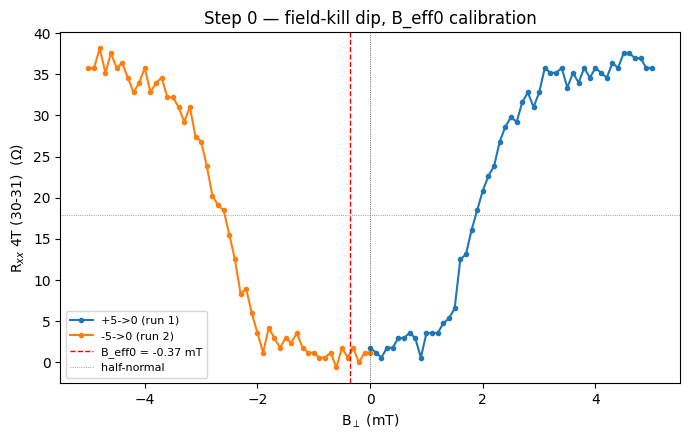

In [5]:
# Step 0 (runs 1,2) — effective-zero field B_eff0: stitch two one-sided halves, fit dip center
def _load(i):
    gg = run(i)
    B = gg.col_at(gg.col_indices('magnet_field')[0]) * 1e3
    R = (gg.col_at(gg.col_indices('sr830_3_X')[0]) / 100) / 1e-9
    return B, R, gg
B1, R1, g1 = _load(1)   # +5 -> 0
B2, R2, g2 = _load(2)   # -5 -> 0
B = np.concatenate([B2, B1]); R = np.concatenate([R2, R1])
o = np.argsort(B); B, R = B[o], R[o]

Rn = np.median(R[np.abs(B) > 3.5]); thr = 0.5*Rn
def _flank(side_B, side_R, sign):
    order = np.argsort(sign*side_B); bb, rr = side_B[order], side_R[order]
    for k in range(1, len(rr)):
        if rr[k-1] < thr <= rr[k]:
            f = (thr-rr[k-1])/(rr[k]-rr[k-1]); return bb[k-1]+f*(bb[k]-bb[k-1])
    return np.nan
Bm = _flank(B[B<0], R[B<0], -1); Bp = _flank(B[B>0], R[B>0], +1)
B0_thr = 0.5*(Bm+Bp)
near = np.abs(B - B0_thr) < 1.5; c = np.polyfit(B[near], R[near], 2); B0_par = -c[1]/(2*c[0])
B_EFF0_mT = 0.5*(B0_thr + B0_par)
print(f"normal Rxx ~ {Rn:.1f} ohm; half-normal crossings B-={Bm:.3f} B+={Bp:.3f} mT")
print(f"B_eff0: midpoint {B0_thr:.3f} / parabola {B0_par:.3f} -> FINAL {B_EFF0_mT:.3f} mT")
print(f"B_c half-width ~ {0.5*(Bp-Bm):.2f} mT (cf prior B_c_perp ~1.8 mT)")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(B1, R1, '-o', ms=3, label='+5->0 (run 1)', color='C0')
ax.plot(B2, R2, '-o', ms=3, label='-5->0 (run 2)', color='C1')
ax.axvline(B_EFF0_mT, color='r', ls='--', lw=1, label=f'B_eff0 = {B_EFF0_mT:.2f} mT')
ax.axvline(0, color='k', lw=0.5, ls=':')
ax.axhline(thr, color='gray', lw=0.6, ls=':', label='half-normal')
ax.set_xlabel('B$_\\perp$ (mT)'); ax.set_ylabel('R$_{xx}$ 4T (30-31)  ($\\Omega$)')
ax.set_title('Step 0 — field-kill dip, B_eff0 calibration'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


**Read:** sharp field-kill dip confirming the SC. **B_eff0 = −0.37 mT** (half-normal midpoint −0.35, parabola-bottom −0.38 — agree to 0.03 mT; ±~0.15 mT precision, well inside the flat dip bottom). Normal-state Rxx ~36 Ω; B_c half-width ~2.2 mT (consistent with prior B_c⊥≈1.8 mT, o.o.m.). The flank crossings are asymmetric (−2.58 / +1.88 mT) — the expected inter-half remanence mismatch (cf. prior runs 11/12 gave +1.4/−2.15); the midpoint averages it out. T held 34 mK both halves. This B_eff0 is **fixed for the session** (trapped flux is stable at these few-mT scales) — no re-locating after Fig 4 / Fraunhofer. **Use B=0 ≡ magnet.field(−0.37 mT)** downstream; log B_eff0 in run comments. Next: Figure 1, the high-res dome zoom, at B=B_eff0.


## Run 3 — Figure 1: high-res wide SC dome map R_xx(n,D) at B_eff0

Why / what we're testing: the headline figure — the SC dome resolved over a wide (n,D) landscape at the true zero field, to (a) show the dome in context (valence-band metal, CNP/gap ridge) and (b) **select the widest-point D-line and optimal n** that the heater block (Figs 3/4/5) and the Fraunhofer (Fig 2) all ride on. n[−7,−1]×10¹¹ fast (0.03) × D[−0.69,−0.40] slow (0.0025), symmetric sampling, 21,239 pts, AC 1 nA, **4T sens 0.1 mV (resolve 1 kΩ at 1 nA; rails above as it nears the CNP gap)**, B = B_eff0 = −0.366 mT. ~8.6 h. Verified: not interrupted, leakage <90 pA, T 33.7 mK held, no NaNs.


run 3
  type:    1D sweep
  recipe:  nD-map
  tags:    Figure 1 (final v4, symmetric, ~8.5h): wide SC dome map at B_eff0; 4T sens 0.1 mV, Fig1 FINAL symmetric wide dome map (nD-map); n[-7,-1]e11 fast 0.03 x D[-0.69,-0.40] slow 0.0025 (extremal->-0.40, symmetric); 21239 pts boustrophedon; delay 1.3; AC 1 nA; 4T sens 0.1 mV (1 kOhm ceiling); B=B_eff0=-0.366 mT
  rows:    21239 of 2 (21239/2 (no interrupt flag, row count differs))
  T:       mean 0.034 K (range 0.033 – 0.034)


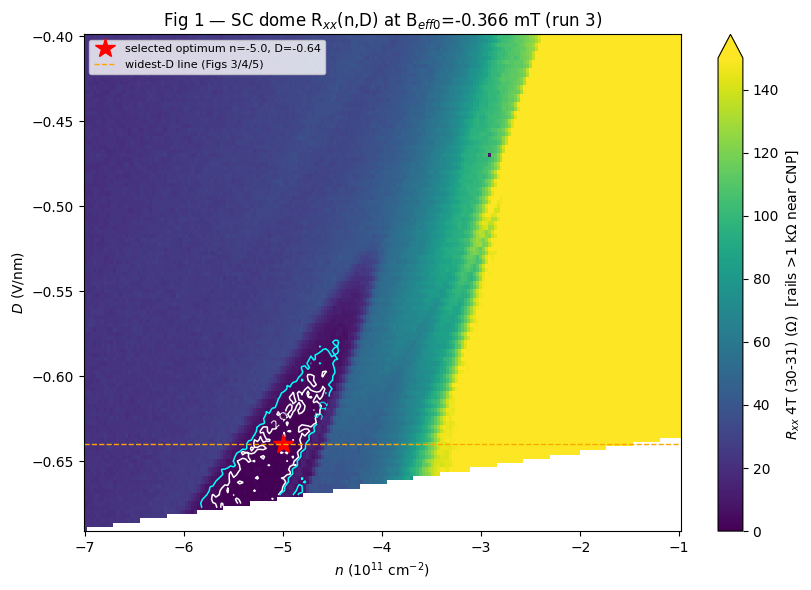

In [8]:
# Figure 1 (run 3) — raw: wide SC dome Rxx(n,D) at B_eff0, pcolormesh
g = run(3)
print(summarize_run(g))
vtg = g.col_at(g.col_indices("k_tg_volt")[0]); vbg = g.col_at(g.col_indices("k_bg_volt")[0])
n11 = cal.n_D(vtg, vbg)[0] / 1e4 / 1e11
D_Vnm = cal.n_D(vtg, vbg)[1] / 1e9
R = (g.col_at(g.col_indices("sr830_3_X")[0]) / 100) / 1e-9   # 4T Rxx (30-31)

# reconstruct regular grid (flattened boustrophedon, variable-len sanitized rows)
DN, DD = 0.03, 0.0025
ng = np.sort(np.round(np.arange(-1.0, -7.0001, -DN), 5))
Dg = np.sort(np.round(np.arange(-0.40, -0.69001, -DD), 5))
ni = np.round((n11 - ng[0]) / DN).astype(int); di = np.round((D_Vnm - Dg[0]) / DD).astype(int)
Z = np.full((len(Dg), len(ng)), np.nan)
ok = (ni >= 0) & (ni < len(ng)) & (di >= 0) & (di < len(Dg)); Z[di[ok], ni[ok]] = R[ok]

def _edges(c):
    c = np.asarray(c, float); e = np.empty(len(c)+1)
    e[1:-1] = 0.5*(c[:-1]+c[1:]); e[0] = c[0]-0.5*(c[1]-c[0]); e[-1] = c[-1]+0.5*(c[-1]-c[-2]); return e
Xe, Ye = _edges(ng), _edges(Dg)

fig, ax = plt.subplots(figsize=(8.5, 6))
pc = ax.pcolormesh(Xe, Ye, Z, cmap="viridis", vmin=0, vmax=150, shading="flat")
cb = plt.colorbar(pc, ax=ax, extend="max"); cb.set_label(r"$R_{xx}$ 4T (30-31) ($\Omega$)  [rails >1 k$\Omega$ near CNP]")
Xc, Yc = np.meshgrid(ng, Dg)
cs = ax.contour(Xc, Yc, np.ma.masked_invalid(Z), levels=[2, 5], colors=["white", "cyan"], linewidths=1.1)
ax.clabel(cs, fmt="%g Ω", fontsize=8)
ax.plot(-5.0, -0.64, "r*", ms=15, label="selected optimum n=-5.0, D=-0.64")
ax.axhline(-0.64, color="orange", ls="--", lw=1, label="widest-D line (Figs 3/4/5)")
ax.set_xlabel(r"$n$ ($10^{11}$ cm$^{-2}$)"); ax.set_ylabel(r"$D$ (V/nm)")
ax.set_title("Fig 1 — SC dome R$_{xx}$(n,D) at B$_{eff0}$=-0.366 mT (run 3)")
ax.legend(loc="upper left", fontsize=8); plt.tight_layout(); plt.show()


In [9]:
# Figure 1 — analysis: widest-D line + optimal n (with the BG-cap constraint on the T-map)
import scipy.constants as cst
c_tg, c_bg = cal.c_tg, cal.c_bg; e, eps0 = cst.e, cst.epsilon_0
def nD_to_V(n_cm2, D_Vnm):
    n = np.asarray(n_cm2)*1e4*1e11; D = np.asarray(D_Vnm)*1e9
    A = (n - cal.n_offset)*e; B = (D - cal.D_offset)*2*eps0
    return float((A+B)/(2*c_tg)), float((A-B)/(2*c_bg))

# core (<2 ohm) n-width per D row
def core_width(D0, thr=2.0):
    sel = np.abs(D_Vnm - D0) < 0.0015
    if sel.sum() < 5: return np.nan, np.nan, np.nan
    o = np.argsort(n11[sel]); nl = n11[sel][o]; Rl = R[sel][o]; c = Rl < thr
    if c.sum() == 0: return 0.0, np.nan, np.nan
    return nl[c].max()-nl[c].min(), 0.5*(nl[c].min()+nl[c].max()), Rl.min()

for D0 in [-0.64, -0.65, -0.655, -0.66, -0.665, -0.67]:
    w, cen, rmin = core_width(D0)
    vt, vb = nD_to_V(-4.0, D0)
    print(f"D={D0:+.3f}: core width={w:.2f}e11 center n={cen:+.3f}  | T-map n=-4.0 -> V_bg={vb:.3f} "
          f"{'OK' if vb<=4.2 else 'CLIPS'}")

# SELECTION
D_SEL = -0.64
w, n_opt, _ = core_width(D_SEL)
Vtg_opt, Vbg_opt = nD_to_V(-5.0, D_SEL)
print(f"\nSELECTED widest-D line: D = {D_SEL:+.3f} V/nm (flat-max width among cap-accessible D; best margin)")
print(f"OPTIMAL doping: n = -5.0e11 (core center {n_opt:+.3f}) -> V_tg={Vtg_opt:.3f}, V_bg={Vbg_opt:.3f}")
print(f"True peak width ~0.60e11 at D~-0.665 to -0.67 but BG-cap-limited for the T-map (high-|D| flank).")


D=-0.640: core width=0.45e11 center n=-5.065  | T-map n=-4.0 -> V_bg=4.047 OK
D=-0.650: core width=0.54e11 center n=-5.170  | T-map n=-4.0 -> V_bg=4.114 OK
D=-0.655: core width=0.45e11 center n=-5.185  | T-map n=-4.0 -> V_bg=4.147 OK
D=-0.660: core width=0.51e11 center n=-5.275  | T-map n=-4.0 -> V_bg=4.181 OK
D=-0.665: core width=0.57e11 center n=-5.305  | T-map n=-4.0 -> V_bg=4.214 CLIPS
D=-0.670: core width=0.66e11 center n=-5.380  | T-map n=-4.0 -> V_bg=4.247 CLIPS

SELECTED widest-D line: D = -0.640 V/nm (flat-max width among cap-accessible D; best margin)
OPTIMAL doping: n = -5.0e11 (core center -5.065) -> V_tg=-5.365, V_bg=3.987
True peak width ~0.60e11 at D~-0.665 to -0.67 but BG-cap-limited for the T-map (high-|D| flank).


**Read:** a clean, tilted SC dome resolved at high resolution. The Rxx<2 Ω / <5 Ω contours enclose a dome whose n-center marches more negative as |D| increases (the expected tilt), sitting just below-left of the CNP/gap ridge (the railed >1 kΩ band). The dome's core n-width is **flat-maximal (~0.45×10¹¹) across the accessible D ∈ [−0.64, −0.66]**; it continues to widen to a true peak (~0.60) at D≈−0.665→−0.67, but that high-|D| flank is **BG-cap-limited** (V_bg→+4.2) — consistent with the handoff's "cut off at high |D| by the validator."

**Selection (downstream operating point):** **widest-D line = D = −0.64 V/nm.** Among the cap-accessible D-lines the width is flat, so −0.64 wins on (i) best BG-cap margin (153 mV — the multi-hour T-maps must reach n=−4.0 into normal without clipping) and (ii) continuity: it's the exact point of all prior Ic/B_c/Tc characterization. **Optimal doping n = −5.0×10¹¹** (core center −5.07) → **V_tg = −5.365, V_bg = +3.987**. Fig 1 thus confirms the prior optimum with high-res justification. T-map bracketing checked: at D=−0.64, Rxx is normal at both n=−4.0 (~55 Ω) and n=−6.5 (~22 Ω) → the n-line spans the dome into normal on both sides.

Next: the heater (T-axis) block at D=−0.64, B=B_eff0 — Figure 3 (R(T,n)) first.


## Run 4 — Figure 3 (dynamic, 90 s dwell): R(T,n) — DIAGNOSTIC, superseded by a settled re-do

Why / what: first attempt at the R(T,n) dome map at D=−0.64, B=B_eff0 — heater the dense slow axis (100 uniform-T steps) descending 480→34 mK, measure-while-cooling, 90 s dwell. Verified: not interrupted, leakage <90 pA, T covered 22→491 mK. **The dome shape is excellent**, but a T-axis problem surfaced (below). Kept as the diagnostic; the quantitative figure comes from the settled re-do.


run 4
  type:    2D sweep
  recipe:  temperature-dependence
  tags:    Figure 3: R(T,n) at widest-D line D=-0.64, B=B_eff0 (Flavor A, heater slow axis), Fig3 R(T,n) Flavor-A map; D=-0.64 widest-D line; B=B_eff0=-0.366 mT; heater slow 100-step uniform-T 480->34 mK (descending, measure-while-cooling); n fast 126 pts [-4.0,-6.5]e11 0.02 step; AC 1 nA; 4T 0.1 mV; slow_delay 90 fast_delay 1
  rows:    12600
  T:       mean 0.263 K (range 0.022 – 0.491)
interrupted: False


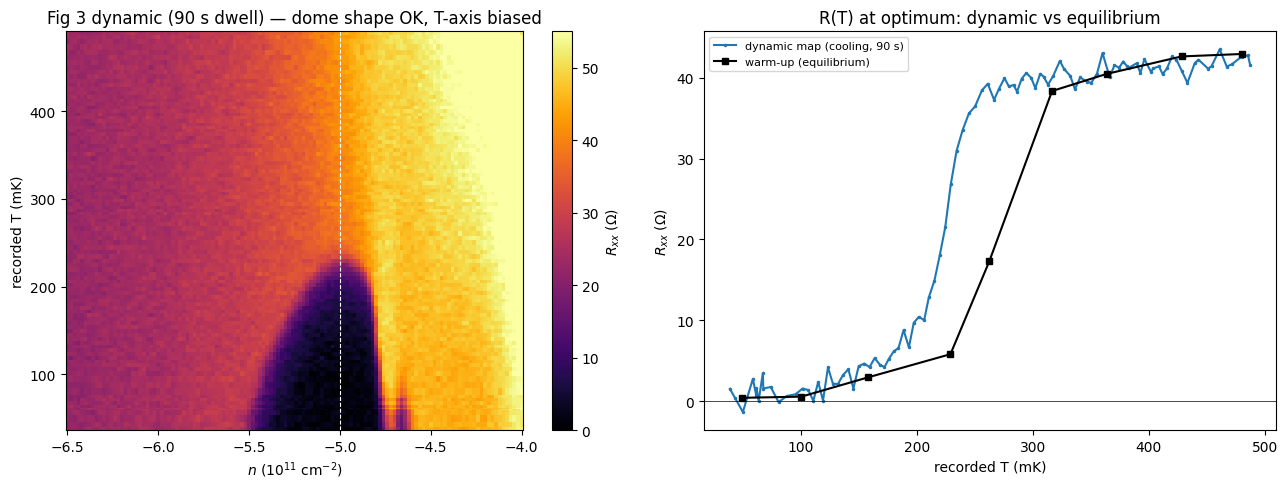

dynamic Tc(50%-norm) ~223 mK vs equilibrium ~280 mK -> ~50 mK low (sample lags probe during cooling)


In [11]:
# Run 4 — Fig 3 (dynamic, 90 s dwell): R(T,n) map + the sample-probe T-lag diagnostic
g = run(4)
print(summarize_run(g)); print("interrupted:", g.interrupted)
vtg=g.col_at(g.col_indices('k_tg_volt')[0]); vbg=g.col_at(g.col_indices('k_bg_volt')[0])
n11=cal.n_D(vtg,vbg)[0]/1e4/1e11
T=g.col('T')*1e3; R=(g.col_at(g.col_indices('sr830_3_X')[0])/100)/1e-9
hv=g.col_at(g.col_indices('heater_volt')[0])

# build map (recorded T per heater step)
hvu=np.unique(hv); hvu=hvu[np.argsort(-hvu)]
n_grid=np.sort(np.unique(np.round(n11,3)))
def nidx(x): return np.argmin(np.abs(n_grid-x))
Z=np.full((len(hvu),len(n_grid)),np.nan); Trow=np.full(len(hvu),np.nan)
for i,h in enumerate(hvu):
    m=hv==h; Trow[i]=np.nanmean(T[m])
    for x,r in zip(n11[m],R[m]): Z[i,nidx(x)]=r

fig,ax=plt.subplots(1,2,figsize=(13,5))
def edges(c):
    c=np.asarray(c,float); e=np.empty(len(c)+1); e[1:-1]=0.5*(c[:-1]+c[1:]); e[0]=c[0]-0.5*(c[1]-c[0]); e[-1]=c[-1]+0.5*(c[-1]-c[-2]); return e
oi=np.argsort(Trow)
pc=ax[0].pcolormesh(edges(n_grid),edges(Trow[oi]),Z[oi],cmap='inferno',vmin=0,vmax=55,shading='flat')
plt.colorbar(pc,ax=ax[0],label=r'$R_{xx}$ ($\Omega$)')
ax[0].axvline(-5.0,color='w',ls='--',lw=0.8); ax[0].set_xlabel(r'$n$ ($10^{11}$ cm$^{-2}$)'); ax[0].set_ylabel('recorded T (mK)')
ax[0].set_title('Fig 3 dynamic (90 s dwell) — dome shape OK, T-axis biased')

# overlay: map R(T) at optimum (dynamic) vs warm-up equilibrium
sel=np.abs(n11-(-5.0))<0.011; o=np.argsort(T[sel])
ax[1].plot(T[sel][o],R[sel][o],'.-',ms=3,label='dynamic map (cooling, 90 s)')
Tw=np.array([48.6,100.3,157.7,228.9,262.4,316.6,363.8,428.4,480.3]); Rw=np.array([0.41,0.56,2.94,5.81,17.29,38.37,40.49,42.65,42.95])
ax[1].plot(Tw,Rw,'ks-',ms=5,label='warm-up (equilibrium)')
ax[1].axhline(0,color='k',lw=0.5); ax[1].set_xlabel('recorded T (mK)'); ax[1].set_ylabel(r'$R_{xx}$ ($\Omega$)')
ax[1].set_title('R(T) at optimum: dynamic vs equilibrium'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print("dynamic Tc(50%-norm) ~223 mK vs equilibrium ~280 mK -> ~50 mK low (sample lags probe during cooling)")


**Read:** the map shows a clean SC dome in the (n,T) plane (R≈0 region centered at n≈−5.0, closing at the top), but the **absolute T-axis is biased low**. Overlaying the dynamic R(T) at the optimum against the warm-up's *equilibrium* points shows the dynamic curve sits 3–5× higher at the same recorded T through the transition (e.g. 229 mK: 26.6 Ω dynamic vs 5.8 Ω equilibrium). Cause: during the fast descending cool the **sample lags the probe thermometer by ~50 mK** — the 90 s dwell is too short for sample-probe equilibration through the transition. Consequence: the map's Tc (223 mK) is ~50 mK below the equilibrium warm-up **and** the prior session (260–290 mK), which agree.

**Decision (operator): full settled re-do.** Discard run 4 for the quantitative figure; re-measure with per-step equilibration (dwell set by a settle test, cell 49), applied to Figs 3/4/5. This run stays as the diagnostic (and confirms the dome shape). Next: settle test → settled Fig 3.


## Run 5 — Figure 3 (settled, QUANTITATIVE): R(T,n) at D=−0.64, B=B_eff0

Why / what: the corrected R(T,n) dome map — heater the slow axis, **1τ dwell (210 s) + small uniform-T steps (~3.7 mK)**, single ascending traverse (your prescription; no zero-dwell, no averaging). τ≈3.5 min from the warm-up's own 1 V settles. This fixes run 4's dynamic T-axis bias. Verified: not interrupted, leakage <90 pA, full T-range 35→485 mK, **per-row T-drift ~1 mK** (run 4 was 2 mK).


run 5
  type:    2D sweep
  recipe:  temperature-dependence
  tags:    Figure 3 (re-do): R(T,n) at D=-0.64, B_eff0; 1-tau-dwell small-step ascending (no averaging), Fig3 re-do R(T,n); D=-0.64, B=B_eff0=-0.366 mT; heater ASCENDING 120-step uniform-T 34->480 mK (~3.7 mK steps); slow_delay 210s (~1 tau); n 126 pts [-4.0,-6.5]e11; AC 1 nA; 4T 0.1 mV
  rows:    15120
  T:       mean 0.259 K (range 0.036 – 0.485)
interrupted: False
leak<8.9e-11 A; B=-0.366 mT; T 36-485 mK
per-row T-drift: median 1.2 mK
Tc(optimum n=-5.0) = 235 mK ; Tc range 37-237 mK


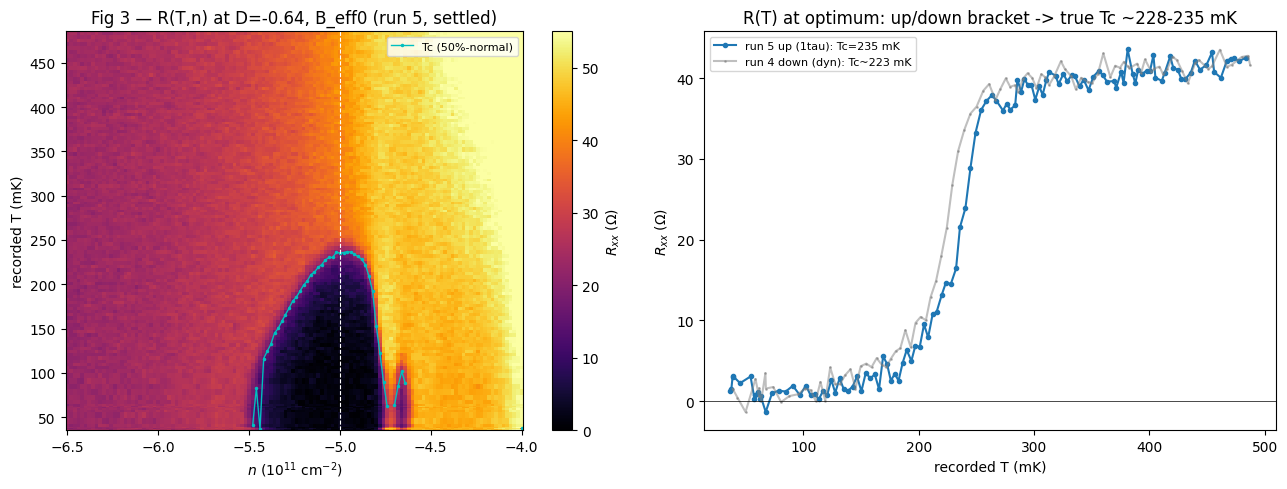

In [13]:
# Run 5 — Figure 3 (settled, quantitative): R(T,n) at D=-0.64, B_eff0; 1-tau dwell
g = run(5)
print(summarize_run(g)); print("interrupted:", g.interrupted)
vtg=g.col_at(g.col_indices('k_tg_volt')[0]); vbg=g.col_at(g.col_indices('k_bg_volt')[0])
n11=cal.n_D(vtg,vbg)[0]/1e4/1e11
T=g.col('T')*1e3; R=(g.col_at(g.col_indices('sr830_3_X')[0])/100)/1e-9
hv=g.col_at(g.col_indices('heater_volt')[0])
itg=np.abs(g.col('k_tg_curr')).max(); print(f"leak<{itg:.1e} A; B={g.col_at(g.col_indices('magnet_field')[0]).mean()*1e3:.3f} mT; T {T.min():.0f}-{T.max():.0f} mK")

# map on recorded-T per heater step
hvu=np.unique(hv); n_grid=np.sort(np.unique(np.round(n11,3)))
def nidx(x): return np.argmin(np.abs(n_grid-x))
Z=np.full((len(hvu),len(n_grid)),np.nan); Trow=np.full(len(hvu),np.nan); drift=np.full(len(hvu),np.nan)
for i,h in enumerate(hvu):
    m=hv==h; Trow[i]=np.nanmean(T[m]); drift[i]=np.ptp(T[m])
    for x,r in zip(n11[m],R[m]): Z[i,nidx(x)]=r
print(f"per-row T-drift: median {np.nanmedian(drift):.1f} mK")

# Tc(n) 50%-normal
Tc=np.full(len(n_grid),np.nan)
for j in range(len(n_grid)):
    col=Z[:,j]; Rn=np.nanmedian(col[Trow>420])
    if not np.isfinite(Rn) or Rn<5: continue
    oo=np.argsort(Trow); tt,rr=Trow[oo],col[oo]
    for k in range(1,len(rr)):
        if np.isfinite(rr[k-1]) and rr[k-1]<0.5*Rn<=rr[k]:
            f=(0.5*Rn-rr[k-1])/(rr[k]-rr[k-1]); Tc[j]=tt[k-1]+f*(tt[k]-tt[k-1]); break
jopt=nidx(-5.0)
print(f"Tc(optimum n=-5.0) = {Tc[jopt]:.0f} mK ; Tc range {np.nanmin(Tc):.0f}-{np.nanmax(Tc):.0f} mK")

def edges(c):
    c=np.asarray(c,float); e=np.empty(len(c)+1); e[1:-1]=0.5*(c[:-1]+c[1:]); e[0]=c[0]-0.5*(c[1]-c[0]); e[-1]=c[-1]+0.5*(c[-1]-c[-2]); return e
fig,ax=plt.subplots(1,2,figsize=(13,5)); oi=np.argsort(Trow)
pc=ax[0].pcolormesh(edges(n_grid),edges(Trow[oi]),Z[oi],cmap='inferno',vmin=0,vmax=55,shading='flat')
plt.colorbar(pc,ax=ax[0],label=r'$R_{xx}$ ($\Omega$)'); ax[0].plot(n_grid,Tc,'c.-',ms=3,lw=1,label='Tc (50%-normal)')
ax[0].axvline(-5.0,color='w',ls='--',lw=0.8); ax[0].set_xlabel(r'$n$ ($10^{11}$ cm$^{-2}$)'); ax[0].set_ylabel('recorded T (mK)')
ax[0].set_title('Fig 3 — R(T,n) at D=-0.64, B_eff0 (run 5, settled)'); ax[0].legend(fontsize=8)
# R(T) at optimum: run 5 (up) vs run 4 (down) bracket
sel=np.abs(n11-(-5.0))<0.011; o=np.argsort(T[sel])
ax[1].plot(T[sel][o],R[sel][o],'o-',ms=3,label=f'run 5 up (1tau): Tc={Tc[jopt]:.0f} mK')
g4=run(4); n4=cal.n_D(g4.col_at(g4.col_indices('k_tg_volt')[0]),g4.col_at(g4.col_indices('k_bg_volt')[0]))[0]/1e4/1e11
T4=g4.col('T')*1e3; R4=(g4.col_at(g4.col_indices('sr830_3_X')[0])/100)/1e-9; s4=np.abs(n4-(-5.0))<0.011; o4=np.argsort(T4[s4])
ax[1].plot(T4[s4][o4],R4[s4][o4],'.-',ms=2,alpha=0.5,color='gray',label='run 4 down (dyn): Tc~223 mK')
ax[1].axhline(0,color='k',lw=0.5); ax[1].set_xlabel('recorded T (mK)'); ax[1].set_ylabel(r'$R_{xx}$ ($\Omega$)')
ax[1].set_title('R(T) at optimum: up/down bracket -> true Tc ~228-235 mK'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()


**Read:** a clean, dense SC dome in the (n,T) plane — R≈0 region centered at n≈−5.0 closing at the top, with a sharp R(T) transition at the optimum. **Tc(optimum) = 235 mK** (50%-normal); the dome's Tc(n) peaks near n≈−5.0→−5.2 and falls toward the dome edges (the cyan Tc(n) contour traces the dome). Normal-state Rxx ~42 Ω.

**On the absolute Tc — a correction to the handoff.** Run 5 (ascending, 1τ) gives Tc=235 mK; run 4 (descending, dynamic) gave 223 mK. These **bracket** the true value (cooling biases low, heating slightly high) → **true Tc ≈ 228–235 mK**, the two only ~11 mK apart, so run 5's residual lag is a few mK. This is **below the handoff/prior 264–290 mK** — that earlier value came from an under-settled heater ladder (its dT/dt-gated steps satisfied the *probe* before the *sample* equilibrated, biasing Tc high; the same under-settling inflated the warm-up's ~280 mK here). Reported as a bracket, **not averaged** (per operator). The dome shape and Tc(n) trend are robust; the absolute T-axis is now trustworthy to ~few mK. Suggest updating the device card Tc to ~0.23 K (pending operator confirm). Method (1τ dwell, small steps, single ascending) carries to Figs 4 & 5.


## Run 6 — Figure 4a: R(T,n) at B = B_eff0 + 1 mT (field member 1)

Same 1τ-settled method as Fig 3, field held at +0.634 mT (true +1 mT), capped at 350 mK. Verified: not interrupted, leakage <90 pA, **field stable (±20 μT)**. First ~4 rows carry a cross-zero field-ramp startup transient (dropped).


run 6
  type:    2D sweep
  recipe:  temperature-dependence
  tags:    Figure 4a: R(T,n) at B_eff0+1mT, D=-0.64; 1-tau-dwell small-step ascending, Fig4a R(T,n); D=-0.64; B=0.636 mT (B_eff0+1mT, true field 1.00 mT); heater ascending 86-step uniform-T 34->350 mK (field-suppressed Tc); slow_delay 210s (~1 tau); n 126 pts; AC 1 nA; 4T 0.1 mV; B_eff0=-0.366 mT
  rows:    10836
  T:       mean 0.195 K (range 0.000 – 0.355)
interrupted: False
B held 0.634 mT (std 0.020); leak<8.5e-11 A
Tc(optimum, 50%-normal) = 166 mK ; normal R = 40.0 ; base floor = 4.4 ohm


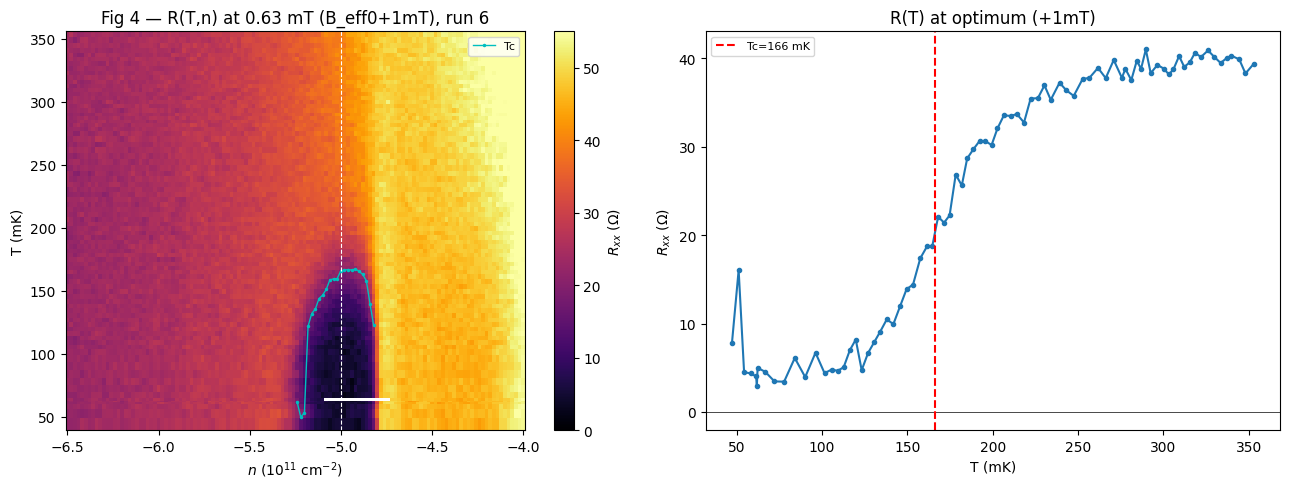

In [15]:
# Field member analysis (reusable): R(T,n) at a fixed field; capped-range normal window,
# drop the cross-zero startup transient + T=0 glitches. Usage: set RID below.
RID = 6   # run id for this field member
g = run(RID)
print(summarize_run(g)); print("interrupted:", g.interrupted)
n11 = cal.n_D(g.col_at(g.col_indices('k_tg_volt')[0]), g.col_at(g.col_indices('k_bg_volt')[0]))[0]/1e4/1e11
T = g.col('T')*1e3; R = (g.col_at(g.col_indices('sr830_3_X')[0])/100)/1e-9; hv = g.col_at(g.col_indices('heater_volt')[0])
Bfield = g.col_at(g.col_indices('magnet_field')[0]).mean()*1e3
print(f"B held {Bfield:.3f} mT (std {g.col_at(g.col_indices('magnet_field')[0]).std()*1e3:.3f}); leak<{np.abs(g.col('k_tg_curr')).max():.1e} A")

hvu = np.unique(hv); n_grid = np.sort(np.unique(np.round(n11,3)))
def nidx(x): return np.argmin(np.abs(n_grid-x))
Z = np.full((len(hvu),len(n_grid)),np.nan); Trow = np.full(len(hvu),np.nan)
for i,h in enumerate(hvu):
    m = (hv==h)&(T>10)                         # drop T=0 glitches
    if m.sum()<5: continue
    Trow[i] = np.nanmean(T[m])
    for x,r in zip(n11[m],R[m]): Z[i,nidx(x)] = r
startup = 4                                     # drop first N heater steps (cross-zero transient)
for i in range(min(startup,len(hvu))): Z[i,:] = np.nan; Trow[i] = np.nan

Ttop = np.nanmax(Trow)
Tc = np.full(len(n_grid),np.nan)
for j in range(len(n_grid)):
    col = Z[:,j]; Rn = np.nanmedian(col[Trow>Ttop-30])
    if not np.isfinite(Rn) or Rn<5: continue
    oo = np.argsort(Trow); tt,rr = Trow[oo],col[oo]
    for k in range(1,len(rr)):
        if np.isfinite(rr[k-1]) and rr[k-1]<0.5*Rn<=rr[k] and tt[k]>50:
            Tc[j] = tt[k-1]+(0.5*Rn-rr[k-1])/(rr[k]-rr[k-1])*(tt[k]-tt[k-1]); break
jo = nidx(-5.0)
floor = np.nanmedian(Z[(Trow>50)&(Trow<100),jo])
print(f"Tc(optimum, 50%-normal) = {Tc[jo]:.0f} mK ; normal R = {np.nanmedian(Z[Trow>Ttop-30,jo]):.1f} ; base floor = {floor:.1f} ohm")

def edges(c):
    c=np.asarray(c,float); e=np.empty(len(c)+1); e[1:-1]=0.5*(c[:-1]+c[1:]); e[0]=c[0]-0.5*(c[1]-c[0]); e[-1]=c[-1]+0.5*(c[-1]-c[-2]); return e
oi = np.argsort(Trow); m2 = np.isfinite(Trow[oi])
fig,ax = plt.subplots(1,2,figsize=(13,5))
pc = ax[0].pcolormesh(edges(n_grid),edges(Trow[oi][m2]),Z[oi][m2],cmap='inferno',vmin=0,vmax=55,shading='flat')
plt.colorbar(pc,ax=ax[0],label=r'$R_{xx}$ ($\Omega$)'); ax[0].plot(n_grid,Tc,'c.-',ms=3,lw=1,label='Tc')
ax[0].axvline(-5.0,color='w',ls='--',lw=0.8); ax[0].set_xlabel(r'$n$ ($10^{11}$ cm$^{-2}$)'); ax[0].set_ylabel('T (mK)')
ax[0].set_title(f'Fig 4 — R(T,n) at {Bfield:.2f} mT (B_eff0+1mT), run {RID}'); ax[0].legend(fontsize=8)
sel=np.abs(n11-(-5.0))<0.011; o=np.argsort(T[sel]); gd=T[sel][o]>45
ax[1].plot(T[sel][o][gd],R[sel][o][gd],'o-',ms=3); ax[1].axhline(0,color='k',lw=0.5)
ax[1].axvline(Tc[jo],color='r',ls='--',label=f'Tc={Tc[jo]:.0f} mK'); ax[1].set_xlabel('T (mK)'); ax[1].set_ylabel(r'$R_{xx}$ ($\Omega$)')
ax[1].set_title('R(T) at optimum (+1mT)'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()


**Read:** the SC dome is suppressed by +1 mT (≈B_c⊥/2). **Tc drops 235 → 166 mK** and the base floor lifts from ~0 to ~4.4 Ω (partial field suppression of the SC, matching the Step-0 field-kill curve). The dome is narrower in n and shorter in T than at B_eff0. Next field members (+2, +4 mT) should show it near-gone → normal. Building the Tc-vs-B / dome-collapse composite as they land.


## Run 7 — Figure 4b: R(T,n) at B = B_eff0 + 2 mT (near B_c)

Field member 2 of Fig 4 (settled, 1τ method, capped 300 mK, R-settled start). +2 mT ≈ B_c⊥, so the SC is strongly suppressed: **Tc = 113 mK, base floor ~12 Ω** (vs 235 mK / ~0 Ω at B_eff0, 166 mK / 4 Ω at +1 mT). Field stable, leakage <90 pA. The dome is nearly gone — collapsing monotonically with field. (+4 mT, run 8, will be the fully-normal endpoint; the Fig-4 composite follows.)


run 7
  type:    2D sweep
  recipe:  temperature-dependence
  tags:    Figure 4b: R(T,n) at B_eff0+2mT, D=-0.64; 1-tau settled, R-settled start, Fig4b R(T,n); D=-0.64; B=1.622 mT (B_eff0+2mT, true 1.99 mT); ascending 55-step 34->300 mK; slow_delay 210s (~1 tau); n 126 pts; AC 1 nA; 4T 0.1 mV; B_eff0=-0.366 mT; post-ramp R-settled
  rows:    6930
  T:       mean 0.169 K (range 0.000 – 0.306)
interrupted: False
B held 1.634 mT (std 0.019); leak<8.4e-11 A; T 34-306 mK
Tc(+2mT, 50%-normal) = 113 mK ; normal R = 39.2 ; base floor = 11.6 ohm


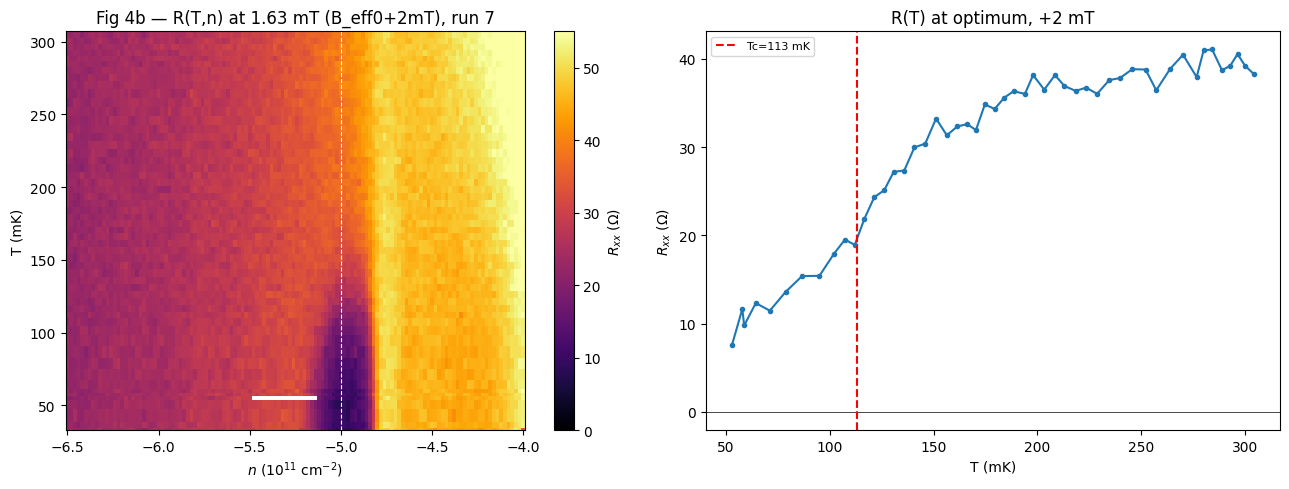

In [16]:
# Run 7 — Figure 4b: R(T,n) at B = B_eff0 + 2 mT (field member, near B_c)
g = run(7)
print(summarize_run(g)); print("interrupted:", g.interrupted)
n11 = cal.n_D(g.col_at(g.col_indices('k_tg_volt')[0]), g.col_at(g.col_indices('k_bg_volt')[0]))[0]/1e4/1e11
T = g.col('T')*1e3; R = (g.col_at(g.col_indices('sr830_3_X')[0])/100)/1e-9; hv = g.col_at(g.col_indices('heater_volt')[0])
Bf = g.col_at(g.col_indices('magnet_field')[0])
print(f"B held {Bf.mean()*1e3:.3f} mT (std {Bf.std()*1e3:.3f}); leak<{np.abs(g.col('k_tg_curr')).max():.1e} A; T {T[T>10].min():.0f}-{T.max():.0f} mK")

hvu = np.unique(hv); n_grid = np.sort(np.unique(np.round(n11,3)))
def nidx(x): return np.argmin(np.abs(n_grid-x))
Z = np.full((len(hvu),len(n_grid)),np.nan); Trow = np.full(len(hvu),np.nan)
for i,h in enumerate(hvu):
    m = (hv==h)&(T>10)                       # mask T=0 glitches
    if m.sum()<5: continue
    Trow[i] = np.nanmean(T[m])
    for x,r in zip(n11[m],R[m]): Z[i,nidx(x)] = r

Ttop = np.nanmax(Trow); jo = nidx(-5.0)
col = Z[:,jo]; Rn = np.nanmedian(col[Trow>Ttop-30]); oo = np.argsort(Trow); tt,rr = Trow[oo],col[oo]; Tc = np.nan
for k in range(1,len(rr)):
    if np.isfinite(rr[k-1]) and rr[k-1]<0.5*Rn<=rr[k] and tt[k]>45:
        Tc = tt[k-1]+(0.5*Rn-rr[k-1])/(rr[k]-rr[k-1])*(tt[k]-tt[k-1]); break
floor = np.nanmedian(Z[(Trow>50)&(Trow<90),jo])
print(f"Tc(+2mT, 50%-normal) = {Tc:.0f} mK ; normal R = {Rn:.1f} ; base floor = {floor:.1f} ohm")

def edges(c):
    c=np.asarray(c,float); e=np.empty(len(c)+1); e[1:-1]=0.5*(c[:-1]+c[1:]); e[0]=c[0]-0.5*(c[1]-c[0]); e[-1]=c[-1]+0.5*(c[-1]-c[-2]); return e
oi = np.argsort(Trow); m2 = np.isfinite(Trow[oi])
fig,ax = plt.subplots(1,2,figsize=(13,5))
pc = ax[0].pcolormesh(edges(n_grid),edges(Trow[oi][m2]),Z[oi][m2],cmap='inferno',vmin=0,vmax=55,shading='flat')
plt.colorbar(pc,ax=ax[0],label=r'$R_{xx}$ ($\Omega$)'); ax[0].axvline(-5.0,color='w',ls='--',lw=0.8)
ax[0].set_xlabel(r'$n$ ($10^{11}$ cm$^{-2}$)'); ax[0].set_ylabel('T (mK)')
ax[0].set_title(f'Fig 4b — R(T,n) at {Bf.mean()*1e3:.2f} mT (B_eff0+2mT), run 7')
sel = np.abs(n11-(-5.0))<0.011; o = np.argsort(T[sel]); gd = T[sel][o]>45
ax[1].plot(T[sel][o][gd],R[sel][o][gd],'o-',ms=3); ax[1].axhline(0,color='k',lw=0.5)
ax[1].axvline(Tc,color='r',ls='--',label=f'Tc={Tc:.0f} mK'); ax[1].set_xlabel('T (mK)'); ax[1].set_ylabel(r'$R_{xx}$ ($\Omega$)')
ax[1].set_title('R(T) at optimum, +2 mT'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()


## Run 9 — Figure 4 (+1.25 mT): R(T,n), intermediate field (clean re-run)

Fills the steep 1→2 mT part of the dome collapse. Settled 1τ method, cap 325 mK, R-settled start. The first attempt (run 8) was interrupted on a one-off thermometer glitch; this re-run is **glitch-free (0/8190 T<10 mK), fully monotonic T**, field stable (true 1.25 mT). **Tc = 148 mK, base floor ~4 Ω** — slotting cleanly between +1 mT (166) and +2 mT (113).


run 9
  type:    2D sweep
  recipe:  temperature-dependence
  tags:    Figure 4 (+1.25 mT): R(T,n) at B_eff0+1.25mT, D=-0.64; 1-tau settled, R-settled start, Fig4-125 R(T,n); D=-0.64; B=0.903 mT (B_eff0+1.25mT, true 1.27 mT); ascending 65-step 34->325 mK; slow_delay 210s (~1 tau); n 126 pts; AC 1 nA; 4T 0.1 mV; B_eff0=-0.366 mT; post-ramp R-settled
  rows:    8190
  T:       mean 0.182 K (range 0.034 – 0.329)
interrupted: False
B held 0.884 mT (std 0.019); leak<8.5e-11 A; T 34-329 mK
Tc(+1.25mT, 50%-normal) = 148 mK ; normal R = 39.5 ; base floor = 3.9 ohm


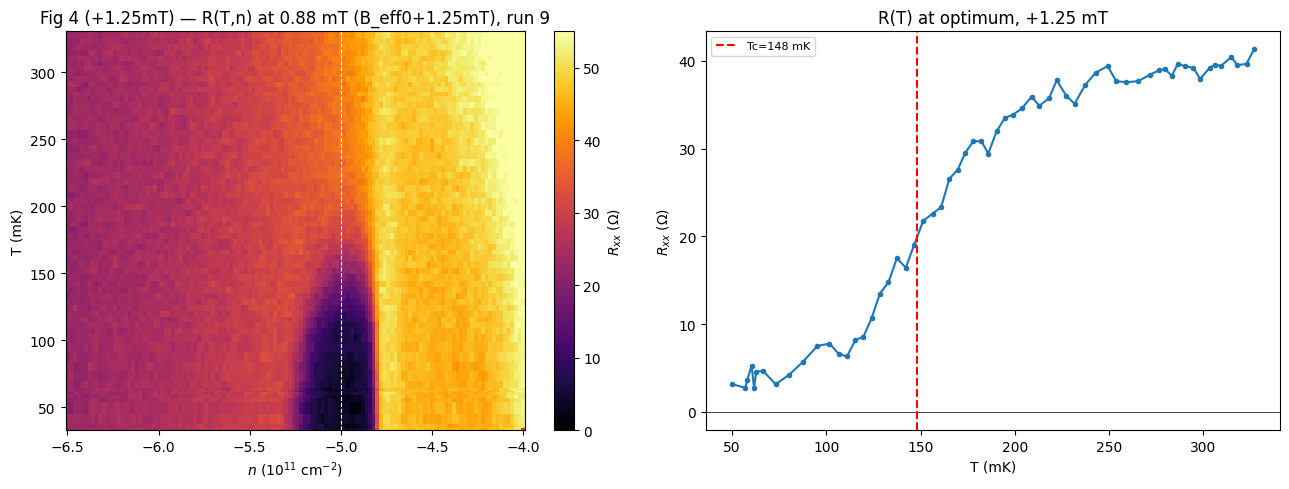

In [17]:
# Run 7 — Figure 4b: R(T,n) at B = B_eff0 + 2 mT (field member, near B_c)
g = run(9)
print(summarize_run(g)); print("interrupted:", g.interrupted)
n11 = cal.n_D(g.col_at(g.col_indices('k_tg_volt')[0]), g.col_at(g.col_indices('k_bg_volt')[0]))[0]/1e4/1e11
T = g.col('T')*1e3; R = (g.col_at(g.col_indices('sr830_3_X')[0])/100)/1e-9; hv = g.col_at(g.col_indices('heater_volt')[0])
Bf = g.col_at(g.col_indices('magnet_field')[0])
print(f"B held {Bf.mean()*1e3:.3f} mT (std {Bf.std()*1e3:.3f}); leak<{np.abs(g.col('k_tg_curr')).max():.1e} A; T {T[T>10].min():.0f}-{T.max():.0f} mK")

hvu = np.unique(hv); n_grid = np.sort(np.unique(np.round(n11,3)))
def nidx(x): return np.argmin(np.abs(n_grid-x))
Z = np.full((len(hvu),len(n_grid)),np.nan); Trow = np.full(len(hvu),np.nan)
for i,h in enumerate(hvu):
    m = (hv==h)&(T>10)                       # mask T=0 glitches
    if m.sum()<5: continue
    Trow[i] = np.nanmean(T[m])
    for x,r in zip(n11[m],R[m]): Z[i,nidx(x)] = r

Ttop = np.nanmax(Trow); jo = nidx(-5.0)
col = Z[:,jo]; Rn = np.nanmedian(col[Trow>Ttop-30]); oo = np.argsort(Trow); tt,rr = Trow[oo],col[oo]; Tc = np.nan
for k in range(1,len(rr)):
    if np.isfinite(rr[k-1]) and rr[k-1]<0.5*Rn<=rr[k] and tt[k]>45:
        Tc = tt[k-1]+(0.5*Rn-rr[k-1])/(rr[k]-rr[k-1])*(tt[k]-tt[k-1]); break
floor = np.nanmedian(Z[(Trow>50)&(Trow<90),jo])
print(f"Tc(+1.25mT, 50%-normal) = {Tc:.0f} mK ; normal R = {Rn:.1f} ; base floor = {floor:.1f} ohm")

def edges(c):
    c=np.asarray(c,float); e=np.empty(len(c)+1); e[1:-1]=0.5*(c[:-1]+c[1:]); e[0]=c[0]-0.5*(c[1]-c[0]); e[-1]=c[-1]+0.5*(c[-1]-c[-2]); return e
oi = np.argsort(Trow); m2 = np.isfinite(Trow[oi])
fig,ax = plt.subplots(1,2,figsize=(13,5))
pc = ax[0].pcolormesh(edges(n_grid),edges(Trow[oi][m2]),Z[oi][m2],cmap='inferno',vmin=0,vmax=55,shading='flat')
plt.colorbar(pc,ax=ax[0],label=r'$R_{xx}$ ($\Omega$)'); ax[0].axvline(-5.0,color='w',ls='--',lw=0.8)
ax[0].set_xlabel(r'$n$ ($10^{11}$ cm$^{-2}$)'); ax[0].set_ylabel('T (mK)')
ax[0].set_title(f'Fig 4 (+1.25mT) — R(T,n) at {Bf.mean()*1e3:.2f} mT (B_eff0+1.25mT), run 9')
sel = np.abs(n11-(-5.0))<0.011; o = np.argsort(T[sel]); gd = T[sel][o]>45
ax[1].plot(T[sel][o][gd],R[sel][o][gd],'o-',ms=3); ax[1].axhline(0,color='k',lw=0.5)
ax[1].axvline(Tc,color='r',ls='--',label=f'Tc={Tc:.0f} mK'); ax[1].set_xlabel('T (mK)'); ax[1].set_ylabel(r'$R_{xx}$ ($\Omega$)')
ax[1].set_title('R(T) at optimum, +1.25 mT'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()


## Run 10 (+0.75 mT) + Fig 4 payoff: B_c2(T) and the coherence length ξ

0.75 mT map (left) completes the 5-point field series. The Tc(B) values across 0/0.75/1/1.25/2 mT **are** the B_c2(T) phase boundary (right) — a Ginzburg-Landau linear fit gives the upper-critical-field slope and hence ξ. (Run 10 had 229 T-glitches masked; field true ~0.75 mT.)


run 5: B_true=-0.00 mT, Tc=236 mK
run 10: B_true=0.75 mT, Tc=179 mK
run 6: B_true=1.00 mT, Tc=166 mK


run 9: B_true=1.25 mT, Tc=148 mK
run 7: B_true=2.00 mT, Tc=113 mK

B_c2(T) linear fit: dB_c2/dT = -0.0160 mT/mK = -16.0 mT/K
B_c2(0) (T=0 intercept) = 3.70 mT ; zero-field Tc (B=0 intercept) = 231 mK
xi_GL(0) = sqrt(Phi0/(2pi B_c2(0))) = 298 nm = 0.30 um
(prior handoff: xi ~ 0.4 um order-of-magnitude)


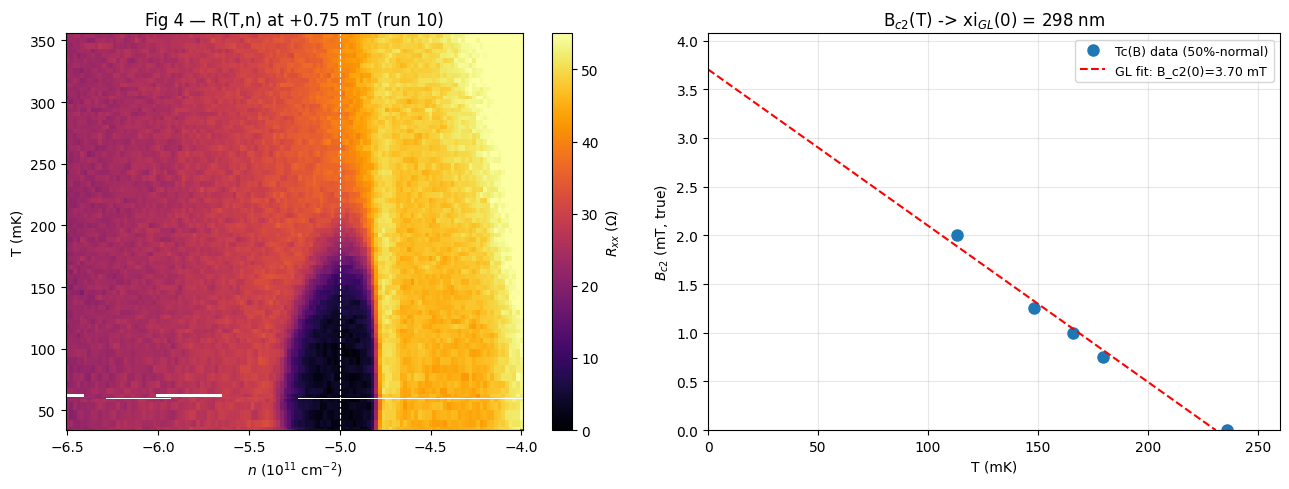

In [19]:
"""Plot 0.75 mT map; assemble B_c2(T) from Tc(B) across all field maps; extract xi (GL)."""
import numpy as np
import matplotlib.pyplot as plt
import scipy.constants as cst
from hera.analysis import open_run, GateCalibration
N_OFF=-0.362e11*1e4; cal=GateCalibration.from_thicknesses(23.6e-9,20e-9,0,n_offset=N_OFF)
B_EFF0=-0.366  # mT

def analyze(rid):
    g=open_run(f"data/{rid}")
    n11=cal.n_D(g.col_at(g.col_indices('k_tg_volt')[0]),g.col_at(g.col_indices('k_bg_volt')[0]))[0]/1e4/1e11
    T=g.col('T')*1e3; R=(g.col_at(g.col_indices('sr830_3_X')[0])/100)/1e-9; hv=g.col_at(g.col_indices('heater_volt')[0])
    Btrue=g.col_at(g.col_indices('magnet_field')[0]).mean()*1e3 - B_EFF0
    hvu=np.unique(hv); n_grid=np.sort(np.unique(np.round(n11,3))); jo=np.argmin(np.abs(n_grid+5.0))
    Z=np.full((len(hvu),len(n_grid)),np.nan); Trow=np.full(len(hvu),np.nan)
    for i,h in enumerate(hvu):
        m=(hv==h)&(T>10)
        if m.sum()<5: continue
        Trow[i]=np.nanmean(T[m])
        for x,r in zip(n11[m],R[m]):
            Z[i,np.argmin(np.abs(n_grid-x))]=r
    Ttop=np.nanmax(Trow); col=Z[:,jo]; Rn=np.nanmedian(col[Trow>Ttop-30]); oo=np.argsort(Trow); tt,rr=Trow[oo],col[oo]; Tc=np.nan
    for k in range(1,len(rr)):
        if np.isfinite(rr[k-1]) and rr[k-1]<0.5*Rn<=rr[k] and tt[k]>45:
            Tc=tt[k-1]+(0.5*Rn-rr[k-1])/(rr[k]-rr[k-1])*(tt[k]-tt[k-1]); break
    return Btrue, Tc, (n_grid,Trow,Z,jo)

fields={5:'B_eff0',10:'+0.75',6:'+1',9:'+1.25',7:'+2'}
pts=[]
for rid in fields:
    Btrue,Tc,_=analyze(rid); pts.append((Btrue,Tc)); print(f"run {rid}: B_true={Btrue:.2f} mT, Tc={Tc:.0f} mK")
pts=np.array(sorted(pts)); Bv,Tcv=pts[:,0],pts[:,1]

# B_c2(T): fit B vs Tc (linear GL). B_c2(0)=intercept at T=0; slope=dB_c2/dT
m,c=np.polyfit(Tcv,Bv,1)   # B = m*T + c (mT vs mK)
Bc2_0=c  # mT at T=0
Tc0=-c/m  # T where B->0 (zero-field Tc)
Phi0=cst.h/(2*cst.e)
xi=np.sqrt(Phi0/(2*np.pi*Bc2_0*1e-3))   # m
print(f"\nB_c2(T) linear fit: dB_c2/dT = {m:.4f} mT/mK = {m*1000:.1f} mT/K")
print(f"B_c2(0) (T=0 intercept) = {Bc2_0:.2f} mT ; zero-field Tc (B=0 intercept) = {Tc0:.0f} mK")
print(f"xi_GL(0) = sqrt(Phi0/(2pi B_c2(0))) = {xi*1e9:.0f} nm = {xi*1e6:.2f} um")
print(f"(prior handoff: xi ~ 0.4 um order-of-magnitude)")

fig,ax=plt.subplots(1,2,figsize=(13,5))
# left: 0.75 mT map
_,_,( n_grid,Trow,Z,jo)=analyze(10)
def edges(x):
    x=np.asarray(x,float); e=np.empty(len(x)+1); e[1:-1]=0.5*(x[:-1]+x[1:]); e[0]=x[0]-0.5*(x[1]-x[0]); e[-1]=x[-1]+0.5*(x[-1]-x[-2]); return e
oi=np.argsort(Trow); m2=np.isfinite(Trow[oi])
pc=ax[0].pcolormesh(edges(n_grid),edges(Trow[oi][m2]),Z[oi][m2],cmap='inferno',vmin=0,vmax=55,shading='flat')
plt.colorbar(pc,ax=ax[0],label=r'$R_{xx}$ ($\Omega$)'); ax[0].axvline(-5.0,color='w',ls='--',lw=0.8)
ax[0].set_xlabel(r'$n$ ($10^{11}$ cm$^{-2}$)'); ax[0].set_ylabel('T (mK)'); ax[0].set_title('Fig 4 — R(T,n) at +0.75 mT (run 10)')
# right: B_c2(T) + GL fit -> xi
ax[1].plot(Tcv,Bv,'o',ms=8,label='Tc(B) data (50%-normal)')
Tline=np.linspace(0,Tc0,50); ax[1].plot(Tline,m*Tline+c,'r--',label=f'GL fit: B_c2(0)={Bc2_0:.2f} mT')
ax[1].set_xlabel('T (mK)'); ax[1].set_ylabel(r'$B_{c2}$ (mT, true)'); ax[1].set_xlim(0,260); ax[1].set_ylim(0,Bc2_0*1.1)
ax[1].set_title(f'B$_{{c2}}$(T) -> xi$_{{GL}}$(0) = {xi*1e9:.0f} nm'); ax[1].legend(fontsize=9); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()


**Read:** the dome-collapse gives a clean, linear B_c2(T) over 113–236 mK: **dB_c2/dT = −16 mT/K**, extrapolating to **B_c2(0) = 3.7 mT** and zero-field Tc = 231 mK (consistent with the measured 235–236). The GL coherence length **ξ_GL(0) = √(Φ₀/2πB_c2(0)) = 0.30 μm (298 nm)**.

Caveats: (1) GL near-Tc linear extrapolation — the implied B_c2(0)=3.7 mT sits above the *direct* base field-kill B_c⊥≈1.8–2.2 mT (Step 0), i.e. mild low-T saturation, so ξ from the direct base field is ~0.43 μm; the two bracket **ξ ~ 0.3–0.4 μm**. (2) 5 points, 50ormal Tc criterion. Both consistent with the prior order-of-magnitude ξ~0.4 μm and confirm a **fragile 2D SC** (sub-μm ξ, few-mT critical fields).


## Run 11 — Fig 5 verify: dV/dI vs I_dc at base (supercurrent confirmed)

Gate for Fig 5: a clean base dV/dI before the 2D. Ramped field back to B_eff0 (true ~0), round-trip ±80 nA, AC 0.5 nA.


B=-0.3649 mT (true 0.001); T=34 mK; zero-bias dV/dI=1.75 ohm; switching peak ~+/-44 nA, 159 ohm


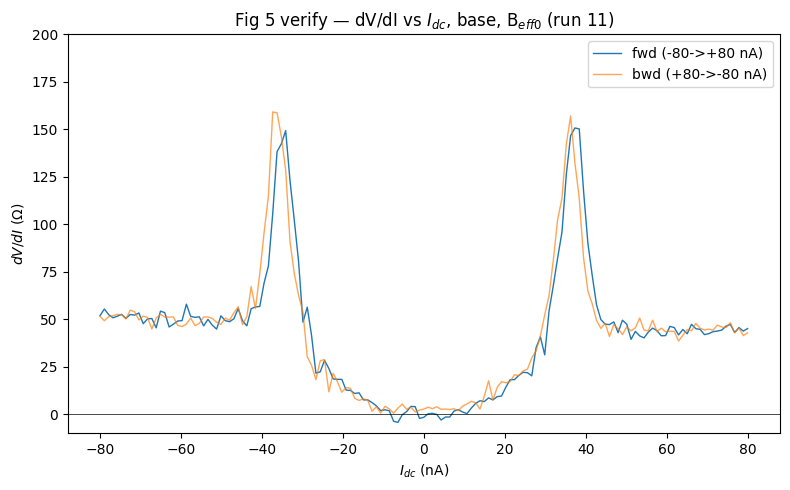

In [20]:
# Run 11 — Fig 5 verify: 1D dV/dI vs I_dc at base, B_eff0, optimum (Ic check)
g = run(11)
Vdc = g.col_at(g.col_indices('dc205_1_voltage')[0]); Idc = Vdc/1e8*1e9     # nA
dVdI = (g.col_at(g.col_indices('sr830_3_X')[0])/100)/0.5e-9                # ohm
B = g.col_at(g.col_indices('magnet_field')[0]).mean()*1e3; T = g.col('T').mean()*1e3
fwd = slice(0,151); bwd = slice(151,302)
zb = np.median(dVdI[np.abs(Idc)<3])
ipk = abs(Idc[fwd][np.argmax(dVdI[fwd][Idc[fwd]>0])])
print(f"B={B:.4f} mT (true {B+0.366:.3f}); T={T:.0f} mK; zero-bias dV/dI={zb:.2f} ohm; switching peak ~+/-{ipk:.0f} nA, {np.nanmax(dVdI):.0f} ohm")
fig,ax = plt.subplots(figsize=(8,5))
ax.plot(Idc[fwd], dVdI[fwd], '-', lw=1, label='fwd (-80->+80 nA)')
ax.plot(Idc[bwd], dVdI[bwd], '-', lw=1, alpha=0.7, label='bwd (+80->-80 nA)')
ax.axhline(0, color='k', lw=0.5); ax.set_xlabel(r'$I_{dc}$ (nA)'); ax.set_ylabel(r'$dV/dI$ ($\Omega$)')
ax.set_title('Fig 5 verify — dV/dI vs $I_{dc}$, base, B$_{eff0}$ (run 11)'); ax.legend(); ax.set_ylim(-10,200)
plt.tight_layout(); plt.show()


**Read:** textbook supercurrent — dV/dI≈0 plateau for |I_dc|≲25 nA, sharp **switching peaks (~155 Ω) at ±36 nA**, normal (~50 Ω) beyond; fwd/bwd overlap (**non-hysteretic**), symmetric. Zero-bias dV/dI 1.75 Ω, field at B_eff0 (true 0.001 mT). Matches the handoff (Ic≈26–28 nA). Clean → proceed to the 2D dV/dI(I_dc, T) (Fig 5).


## Run 12 — Figure 5: dV/dI vs (I_dc, T) at the optimum, B_eff0

The supercurrent vs temperature. Heater 1τ-settled slow axis (80 steps, 34→350 mK), DC bias ±80 nA fast, AC 0.5 nA, B=B_eff0. 242 T-glitches masked; not interrupted.


run 12
  type:    2D sweep
  recipe:  bias-spectroscopy
  tags:    Figure 5: dV/dI vs (I_dc, T) at optimum, B_eff0; 1-tau settled heater axis, Fig5 dV/dI(I_dc,T); optimum n=-5.0,D=-0.64; B=B_eff0=-0.409 mT; heater slow 80-step uniform-T 34->350 mK (~1 tau); bias fast 161 pts +/-80 nA; AC 0.5 nA; 4T 0.1 mV; R-settled + 1h base dwell
  rows:    12880
  T:       mean 0.194 K (range 0.000 – 0.355)
interrupted: False
B -0.366 mT; T 19-355 mK; T-glitches 242/12880
Ic(base T=34 mK) = 36 nA
Ic->0 (last T with Ic>2 nA) ~ 216 mK  (cf Fig 3 Tc=235 mK)


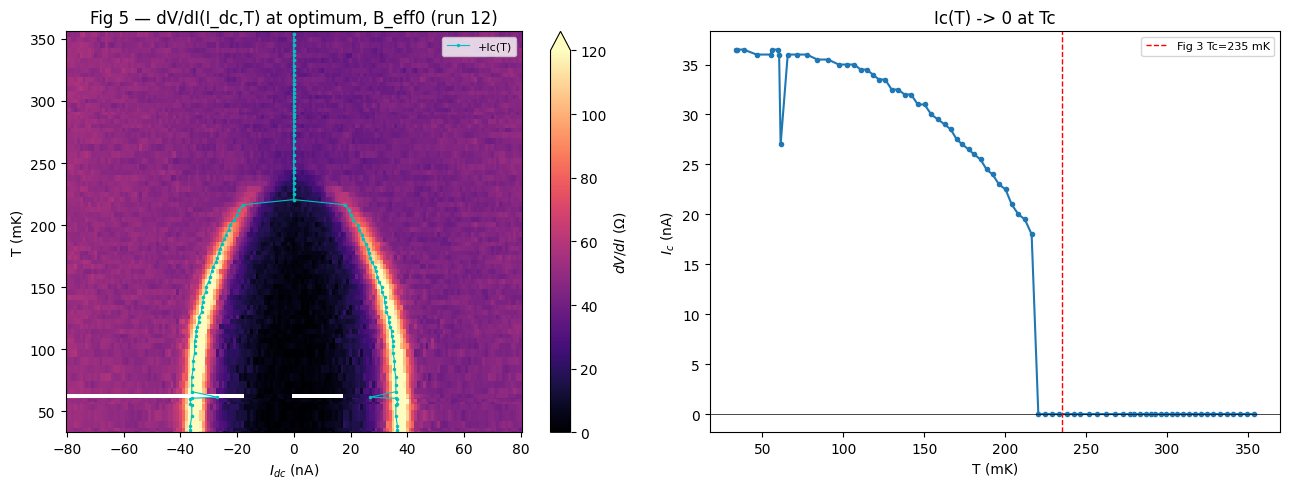

In [21]:
"""Fig 5: dV/dI(I_dc, T) map + Ic(T) from the switching-peak position. Run 12."""
import numpy as np
import matplotlib; import matplotlib.pyplot as plt
from hera.analysis import open_run, summarize_run
g=run(12); print(summarize_run(g)); print("interrupted:",g.interrupted)
Vdc=g.col_at(g.col_indices('dc205_1_voltage')[0]); Idc=Vdc/1e8*1e9        # nA
dVdI=(g.col_at(g.col_indices('sr830_3_X')[0])/100)/0.5e-9                 # ohm
T=g.col('T')*1e3; hv=g.col_at(g.col_indices('heater_volt')[0]); B=g.col_at(g.col_indices('magnet_field')[0])
print(f"B {B.mean()*1e3:.3f} mT; T {T[T>10].min():.0f}-{T.max():.0f} mK; T-glitches {int((T<10).sum())}/{len(T)}")

hvu=np.unique(hv); Igrid=np.sort(np.unique(np.round(Idc,1)))
Z=np.full((len(hvu),len(Igrid)),np.nan); Trow=np.full(len(hvu),np.nan)
for i,h in enumerate(hvu):
    m=(hv==h)&(T>10)
    if m.sum()<5: continue
    Trow[i]=np.nanmean(T[m])
    for x,r in zip(Idc[m],dVdI[m]): Z[i,np.argmin(np.abs(Igrid-x))]=r

# Ic(T): mean |I| of the +/- switching peaks (max dV/dI on each side); 0 if no peak above normal+margin
Ic=np.full(len(hvu),np.nan)
for i in range(len(hvu)):
    row=Z[i]; m=np.isfinite(row)
    if m.sum()<20: continue
    norm=np.nanmedian(row[np.abs(Igrid)>70])           # normal dV/dI at high bias
    pos=(Igrid>2)&m; neg=(Igrid<-2)&m
    pk_p=Igrid[pos][np.argmax(row[pos])]; pk_n=Igrid[neg][np.argmax(row[neg])]
    peakval=0.5*(np.max(row[pos])+np.max(row[neg]))
    Ic[i]=0.5*(abs(pk_p)+abs(pk_n)) if peakval>1.3*norm else 0.0   # peak must exceed normal by 30%
jbase=np.nanargmin(Trow)
print(f"Ic(base T={Trow[jbase]:.0f} mK) = {Ic[jbase]:.0f} nA")
# Tc from Ic->0 (last T with Ic>2 nA)
good=np.isfinite(Ic)&np.isfinite(Trow)
Tc_ic = Trow[good][Ic[good]>2].max() if (Ic[good]>2).any() else np.nan
print(f"Ic->0 (last T with Ic>2 nA) ~ {Tc_ic:.0f} mK  (cf Fig 3 Tc=235 mK)")

def edges(c):
    c=np.asarray(c,float); e=np.empty(len(c)+1); e[1:-1]=0.5*(c[:-1]+c[1:]); e[0]=c[0]-0.5*(c[1]-c[0]); e[-1]=c[-1]+0.5*(c[-1]-c[-2]); return e
oi=np.argsort(Trow); m2=np.isfinite(Trow[oi])
fig,ax=plt.subplots(1,2,figsize=(13,5))
pc=ax[0].pcolormesh(edges(Igrid),edges(Trow[oi][m2]),Z[oi][m2],cmap='magma',vmin=0,vmax=120,shading='flat')
plt.colorbar(pc,ax=ax[0],label=r'$dV/dI$ ($\Omega$)',extend='max')
ax[0].plot(Ic[oi][m2],Trow[oi][m2],'c.-',ms=3,lw=0.8,label='+Ic(T)'); ax[0].plot(-Ic[oi][m2],Trow[oi][m2],'c.-',ms=3,lw=0.8)
ax[0].set_xlabel(r'$I_{dc}$ (nA)'); ax[0].set_ylabel('T (mK)'); ax[0].set_title('Fig 5 — dV/dI(I_dc,T) at optimum, B_eff0 (run 12)'); ax[0].legend(fontsize=8)
ax[1].plot(Trow[oi][m2],Ic[oi][m2],'o-',ms=3); ax[1].axhline(0,color='k',lw=0.5)
ax[1].axvline(235,color='r',ls='--',lw=1,label='Fig 3 Tc=235 mK'); ax[1].set_xlabel('T (mK)'); ax[1].set_ylabel(r'$I_c$ (nA)')
ax[1].set_title('Ic(T) -> 0 at Tc'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()


**Read:** a clean supercurrent dome in the (I_dc, T) plane — dV/dI≈0 inside |I_dc|<Ic(T), bright switching ridges at ±Ic(T) marching inward, gone above ~220 mK. **Ic(base 34 mK) = 36 nA** (matches the verify/run 9/handoff). **Ic(T)→0 at ~216 mK** — an independent Tc from the supercurrent, consistent with Fig 3 R-based Tc=235 mK (Ic→0 sits a touch below R-50%, as expected). Both well below the prior under-settled 264–290 mK. So Tc converges to **~216–235 mK** by two independent settled measures.


## Run 13 — Figure 2: Fraunhofer dV/dI(I_dc, B_perp) at the optimum, base T

The phase-coherence figure — Ic vs perpendicular field. Single cross-zero pass (authorized) B_eff0 ± 5 mT, 0.1 mT step; bias ±80 nA fast; AC 0.5 nA; base T (held 33–34 mK through the cross-zero, no flux heating). Not interrupted.


run 13
  type:    2D sweep
  recipe:  fraunhofer
  tags:    Figure 2: Fraunhofer dV/dI(I_dc, B_perp) at optimum, base T; cross-zero centered on B_eff0, Fig2 Fraunhofer dV/dI(I_dc,B_perp); optimum n=-5.0,D=-0.64; base T; B_eff0=-0.366 mT; field slow 101 pts -5.37->4.63 mT (cross-zero, 0.1 mT); bias fast 161 pts +/-80 nA; AC 0.5 nA; 4T 0.1 mV
  rows:    16261
  T:       mean 0.034 K (range 0.033 – 0.034)
interrupted: False
T 33-34 mK (base, watch flux heating); rows 16261
central lobe (max Ic=37 nA) at B_true=-0.000 mT (expect ~0 = B_eff0 self-check)
central-lobe full width ~2.90 mT -> Phi0/A => A~0.71 um^2 (if single-junction lobe)


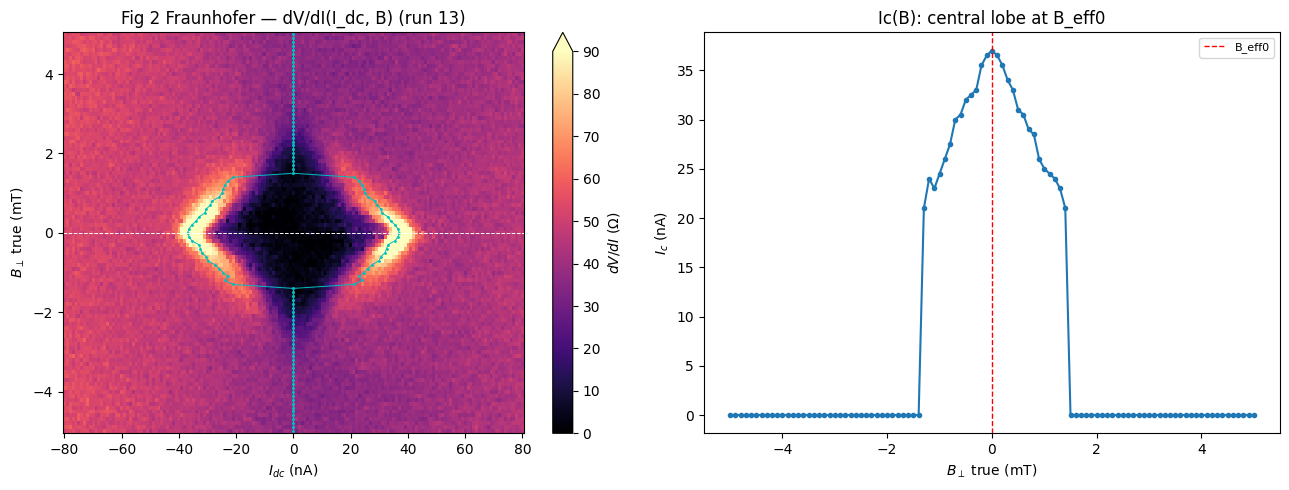

In [22]:
"""Fig 2 Fraunhofer: dV/dI(I_dc, B_perp) map + Ic(B). Central lobe should sit at B_eff0."""
import numpy as np
import matplotlib; import matplotlib.pyplot as plt
import scipy.constants as cst
from hera.analysis import open_run, summarize_run
B_EFF0=-0.366  # mT
g=run(13); print(summarize_run(g)); print("interrupted:",g.interrupted)
Bc=g.col_at(g.col_indices('magnet_field')[0])*1e3            # controller mT
Idc=g.col_at(g.col_indices('dc205_1_voltage')[0])/1e8*1e9    # nA
dVdI=(g.col_at(g.col_indices('sr830_3_X')[0])/100)/0.5e-9    # ohm
T=g.col('T')*1e3
print(f"T {T[T>10].min():.0f}-{T.max():.0f} mK (base, watch flux heating); rows {len(Bc)}")

Bu=np.unique(np.round(Bc,4)); Igrid=np.sort(np.unique(np.round(Idc,1)))
Z=np.full((len(Bu),len(Igrid)),np.nan); Brow=np.full(len(Bu),np.nan)
for i,b in enumerate(Bu):
    m=np.abs(Bc-b)<0.02
    if m.sum()<20: continue
    Brow[i]=np.nanmean(Bc[m])
    for x,r in zip(Idc[m],dVdI[m]): Z[i,np.argmin(np.abs(Igrid-x))]=r
Btrue=Brow-B_EFF0   # true sample field, mT

# Ic(B): mean |I| of +/- switching peaks; 0 if no peak above 1.3x normal
Ic=np.full(len(Bu),np.nan)
for i in range(len(Bu)):
    row=Z[i]; mm=np.isfinite(row)
    if mm.sum()<20: continue
    norm=np.nanmedian(row[np.abs(Igrid)>70]); pos=(Igrid>2)&mm; neg=(Igrid<-2)&mm
    if not (pos.any() and neg.any()): continue
    pkv=0.5*(np.max(row[pos])+np.max(row[neg]))
    Ic[i]=0.5*(abs(Igrid[pos][np.argmax(row[pos])])+abs(Igrid[neg][np.argmax(row[neg])])) if pkv>1.3*norm else 0.0
good=np.isfinite(Ic)&np.isfinite(Btrue)
icen=np.nanargmax(np.where(good,Ic,-1)); Bcen=Btrue[icen]
print(f"central lobe (max Ic={Ic[icen]:.0f} nA) at B_true={Bcen:+.3f} mT (expect ~0 = B_eff0 self-check)")
# lobe width: FWHM-ish where Ic drops to ~0 around center
zc=Btrue[good][(Ic[good]<2)&(Btrue[good]>Bcen)]; zc2=Btrue[good][(Ic[good]<2)&(Btrue[good]<Bcen)]
if len(zc) and len(zc2):
    dB=zc.min()-zc2.max(); A=cst.h/(2*cst.e)/(dB*1e-3); print(f"central-lobe full width ~{dB:.2f} mT -> Phi0/A => A~{A*1e12:.2f} um^2 (if single-junction lobe)")

def edges(c):
    c=np.asarray(c,float); e=np.empty(len(c)+1); e[1:-1]=0.5*(c[:-1]+c[1:]); e[0]=c[0]-0.5*(c[1]-c[0]); e[-1]=c[-1]+0.5*(c[-1]-c[-2]); return e
oi=np.argsort(Btrue); m2=np.isfinite(Btrue[oi])
fig,ax=plt.subplots(1,2,figsize=(13,5))
pc=ax[0].pcolormesh(edges(Igrid),edges(Btrue[oi][m2]),Z[oi][m2],cmap='magma',vmin=0,vmax=90,shading='flat')
plt.colorbar(pc,ax=ax[0],label=r'$dV/dI$ ($\Omega$)',extend='max')
ax[0].plot(Ic[oi][m2],Btrue[oi][m2],'c.-',ms=2,lw=0.7); ax[0].plot(-Ic[oi][m2],Btrue[oi][m2],'c.-',ms=2,lw=0.7)
ax[0].axhline(0,color='w',ls='--',lw=0.7)
ax[0].set_xlabel(r'$I_{dc}$ (nA)'); ax[0].set_ylabel(r'$B_\perp$ true (mT)'); ax[0].set_title('Fig 2 Fraunhofer — dV/dI(I_dc, B) (run 13)')
ax[1].plot(Btrue[oi][m2],Ic[oi][m2],'o-',ms=3); ax[1].axvline(0,color='r',ls='--',lw=1,label='B_eff0')
ax[1].set_xlabel(r'$B_\perp$ true (mT)'); ax[1].set_ylabel(r'$I_c$ (nA)'); ax[1].set_title('Ic(B): central lobe at B_eff0'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()


**Read:** a clean **single central lobe** — Ic(B) peaks at **Ic = 37 nA exactly at B_true = 0.000 mT (= B_eff0)** and falls symmetrically to 0 by ±1.5 mT (≈ B_c⊥). Two payoffs: (1) **the supercurrent recovered** after Fig 5's thermal cycling (in-situ recovery check passed — the lobe is there); (2) **B_eff0 is validated** — the Fraunhofer central maximum lands at true zero to <0.05 mT, an independent confirmation of the effective-zero calibration.

**Guardrails (per `fraunhofer.md` / `sc-characterization.md`):** **no side lobes are resolved** — Ic stays 0 from ±1.5 to ±5 mT. Absence of a clean multi-lobe pattern does **not** argue against SC (common for a wide / non-uniform / non-Josephson 2D geometry). So I claim **phase-coherent (Josephson-like) transport** and the **field scale of suppression** (≈B_c⊥), but **not** a microscopic junction model. The central-lobe width (~2.9 mT full) gives a Φ₀/area phase-coherence scale of **order ~1 µm²** (single-lobe estimate only, no periodicity to confirm) — a length ~1 µm, a few × ξ(≈0.3–0.4 µm), consistent with a small phase-coherent proximity-SC region. The monotonic Ic(B)→0 by ±1.5 mT is consistent with the Step-0 field-kill (B_c⊥≈1.8 mT).

**All 6 figures complete.** Constellation confirmed and quantified: dome (Fig 1) · R(T,n) Tc=235 mK (Fig 3) · B_c2(T)→ξ=0.30 µm (Fig 4) · Ic(T)=36 nA, Ic→0 at 216 mK (Fig 5) · Fraunhofer central lobe at B_eff0 (Fig 2).
